https://arxiv.org/abs/2411.07191

https://github.com/mengxiayu/LLMSuperWeight/blob/main/analyze.py

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

In [2]:
def check_module_hidden_states(model, tokenizer, test_text, layer_path, module_name, input_or_output="output", plot_fname=None, spike_threshold=100):
    if input_or_output not in ["input", "output"]:
        raise ValueError("input_or_output should be 'input' or 'output', instead of", input_or_output)
    all_activations = {}

    def get_activations(layer_index):
        def hook(model, inputs, outputs):
            hidden_states = inputs if input_or_output == "input" else outputs
            all_activations.setdefault(layer_index, {})[f"{module_name}_{input_or_output}_hidden_states"] = hidden_states
        return hook   

    all_hooks = []

    def get_layers(model, layer_path):
        attributes = layer_path.split('.')
        layers = model
        for attr in attributes:
            layers = getattr(layers, attr)
        return layers

    attributes = module_name.split('.') if module_name != "layer" else []
    layers = get_layers(model, layer_path)

    for layer_index, layer in enumerate(layers):
        current_attr = layer
        valid = True
        for attr in attributes:
            if hasattr(current_attr, attr):
                current_attr = getattr(current_attr, attr)
            else:
                valid = False
                break
        
        if valid:
            hook = current_attr.register_forward_hook(get_activations(layer_index))
            all_hooks.append(hook)

    inputs = tokenizer(test_text, return_tensors='pt').to(model.device)
    model.eval()
    with torch.no_grad():
        model(**inputs)

    for hook in all_hooks:
        hook.remove()

    top1_values_all_layers = []
    top1_indexes_all_layers = []
    for layer_index, outputs in all_activations.items():
        values = outputs[f'{module_name}_{input_or_output}_hidden_states']
        tensor = values[0] if isinstance(values, tuple) else values
        tensor = tensor.detach().cpu()
        tensor_abs = tensor.view(-1).abs().float()

        max_value, max_index = torch.max(tensor_abs, 0)
        max_index = torch.unravel_index(max_index, tensor.shape)
        top1_values_all_layers.append(tensor[max_index])
        top1_indexes_all_layers.append(max_index)

    return top1_values_all_layers, top1_indexes_all_layers


def add_global_plot_styles(multiplier=1):
    plt.rcParams["font.family"] = "serif"
    plt.grid(color='#CCCCCC', linestyle='--')
    plt.rcParams.update({
        'axes.titlesize': 17 * multiplier,
        'axes.labelsize': 15 * multiplier,
        'xtick.labelsize': 10 * multiplier,
        'ytick.labelsize': 10 * multiplier,
    })
    plt.tight_layout()

In [3]:
def scale_SO(model, pretrained, SO_values, scaling_factor):
    for (layer, row, col), value in SO_values.items():  
        old_value = model.model.layers[layer].mlp.down_proj.weight.data[row, col].item()
        new_value = value * scaling_factor
        model.model.layers[layer].mlp.down_proj.weight.data[row, col] = new_value
        print(f"Layer {layer}, Index [{row}, {col}], Old value: {old_value}, New value: {new_value}")


def record_SO(model, pretrained, SUPER_WEIGHTS_MAP):
    '''Record SO values for original models'''
    
    def _record_SO(SO_map, layer, row, col):
        SO_map[(layer, row, col)] = model.model.layers[layer].mlp.down_proj.weight.data[row, col].item()

    SO_values = {}
    for model_name, coordinates in SUPER_WEIGHTS_MAP.items():
        if model_name in pretrained:
            for layer, row, col in coordinates:
                _record_SO(SO_values, layer, row, col)
            break
    return SO_values


def plot_max_activation_ablation(pretrained="HuggingFaceTB/SmolLM2-1.7B"):
    model = AutoModelForCausalLM.from_pretrained(pretrained, trust_remote_code=True, torch_dtype=torch.float16)
    tokenizer = AutoTokenizer.from_pretrained(pretrained, trust_remote_code=True)

    
    test_text = "A cat sat quietly on the windowsill."
    layer_path = "model.layers"
    module_name = "layer"
    name = "output"
    # original
    magnitude, index = check_module_hidden_states(
            model, tokenizer, test_text, layer_path, module_name, input_or_output=name, spike_threshold=50)
    # Print output magnitudes
    print(f"original={list(map(float, magnitude))}")
    original = magnitude
    
    # remove SO
    SO_values = record_SO(model, pretrained)
    scale_SO(model, pretrained, SO_values, 0)
    magnitude, index = check_module_hidden_states(
            model, tokenizer, test_text, layer_path, module_name, input_or_output=name, spike_threshold=50)
    # Report any spikes
    spikes_input = [i for i, value in enumerate(magnitude) if abs(value) > 50]
    print(f"Activation spikes for {module_name} {name}:")
    for i in spikes_input:
        spike_index = index[i]
        print(f" - layer {i}, value {magnitude[i]}, index {tuple(i.item() for i in spike_index)}")
    # Print output magnitudes
    print(f"super_weight_removed={list(map(float, magnitude))}")
    super_weight_removed = magnitude

    # remove outliers
    percentage = 5e-7
    remove_outliers(model, pretrained, percentage)
    magnitude, index = check_module_hidden_states(
            model, tokenizer, test_text, layer_path, module_name, input_or_output=name, spike_threshold=50)
    # Print output magnitudes
    print(f"all_outliers_removed={list(map(float, magnitude))}")
    all_outliers_removed = magnitude

    # restore SO
    scale_SO(model, pretrained, SO_values, 1)
    magnitude, index = check_module_hidden_states(
            model, tokenizer, test_text, layer_path, module_name, input_or_output=name, spike_threshold=50)
    # Print output magnitudes
    print(f"all_other_outliers_removed={list(map(float, magnitude))}")
    all_other_outliers_removed = magnitude
    return original, super_weight_removed, all_outliers_removed, all_other_outliers_removed


def remove_outliers(model, pretrained, percentage_threshold):

    num_selected_elements = []
    for name, param in model.named_parameters():
        if not name.endswith("weight"):
            continue

        weight = param.data
        num_top_elements = int(weight.numel() * percentage_threshold)
        # print("# Total params:", weight.numel(), "# top params", num_top_elements)
        if num_top_elements < 1: # too few elements to apply on
            continue 
        threshold = torch.topk(weight.view(-1).abs(), num_top_elements).values[-1]
        mask = weight.abs() >= threshold
        true_indices = mask.nonzero(as_tuple=False)
        num_selected_elements.append(len(true_indices))

        weight[mask] = 0.
        param = torch.nn.Parameter(weight)  

In [4]:
def plot_down_proj_input_output(pretrained="HuggingFaceTB/SmolLM2-1.7B", module_name="mlp.down_proj", model=None):
    if model is None:
        model = AutoModelForCausalLM.from_pretrained(pretrained, trust_remote_code=True, torch_dtype=torch.float16)
    tokenizer = AutoTokenizer.from_pretrained(pretrained, trust_remote_code=True)

    test_text = "A cat sat quietly on the windowsill."
    layer_path = "model.layers"

    for name in ("input", "output"):
        magnitude, index = check_module_hidden_states(
            model, tokenizer, test_text, layer_path, module_name, input_or_output=name, spike_threshold=50)

        # Report any spikes
        spikes_input = [i for i, value in enumerate(magnitude) if abs(value) > 50]
        print(f"Activation spikes for {module_name} {name}:")
        for i in spikes_input:
            spike_index = index[i]
            print(f" - layer {i}, value {magnitude[i]}, index {tuple(i.item() for i in spike_index)}")

        # Plot input activations
        plt.figure(figsize=(6, 4.5))
        add_global_plot_styles()
        plt.plot(range(len(magnitude)), magnitude, color='blue', marker='o', markersize=5)
        plt.xlabel('Layer Number')
        plt.ylabel('Max Activation Value')
        plt.title(f"OLMo-7B Max {module_name} {name}")
        plt.yticks(rotation=90, va='center')


        # Print output magnitudes
        print(f"largest_activations_{module_name}_{name}={list(map(float, magnitude))}")


In [ ]:
original, super_weight_removed, all_outliers_removed, all_other_outliers_removed = plot_max_activation_ablation()

# Removing super-weights one by one
- to identify all of them

In [14]:
from utils import get_opt, get_loaders, eval_ppl

DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')
model_name = pretrained = "HuggingFaceTB/SmolLM2-1.7B"

# model = get_opt(model_name)
# model.eval()
# model.to(DEV)
model = AutoModelForCausalLM.from_pretrained(pretrained, trust_remote_code=True, torch_dtype=torch.float16)
model.seqlen = model.config.max_position_embeddings
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

In [6]:
wiki_dataloader, wiki_testloader = get_loaders(
    'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (2565857 > 8192). Running this sequence through the model will result in indexing errors


ts torch.Size([1, 2565857])


## Original model

In [43]:
eval_ppl(model, wiki_testloader, device=DEV)

7.253218650817871

Activation spikes for mlp.down_proj input:
 - layer 1, value -373.0, index (0, 5, 4987)
 - layer 7, value -2702.0, index (0, 0, 7758)
 - layer 21, value 51.21875, index (0, 1, 4669)
 - layer 22, value -592.0, index (0, 0, 3997)
 - layer 23, value -153.0, index (0, 8, 742)
largest_activations_mlp.down_proj_input=[-5.12109375, -373.0, 3.89453125, -2.474609375, 1.8701171875, 5.1953125, -15.3671875, -2702.0, 3.75390625, 4.76953125, 5.25, 4.64453125, -5.42578125, -4.72265625, 6.46484375, 8.140625, -17.078125, -14.578125, -15.640625, -22.125, -44.53125, 51.21875, -592.0, -153.0]
Activation spikes for mlp.down_proj output:
 - layer 0, value 70.9375, index (0, 0, 227)
 - layer 1, value -2850.0, index (0, 5, 749)
 - layer 6, value 121.0625, index (0, 0, 749)
 - layer 7, value 25056.0, index (0, 0, 227)
 - layer 17, value -83.0, index (0, 1, 749)
 - layer 18, value -169.25, index (0, 1, 749)
 - layer 19, value -161.5, index (0, 1, 749)
 - layer 20, value -214.5, index (0, 1, 749)
 - layer 21, va

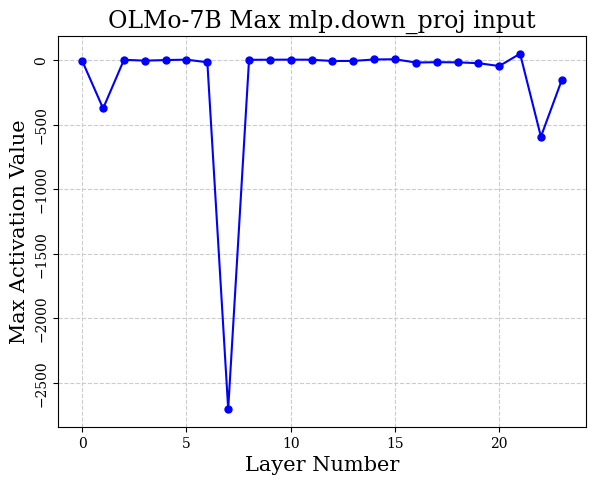

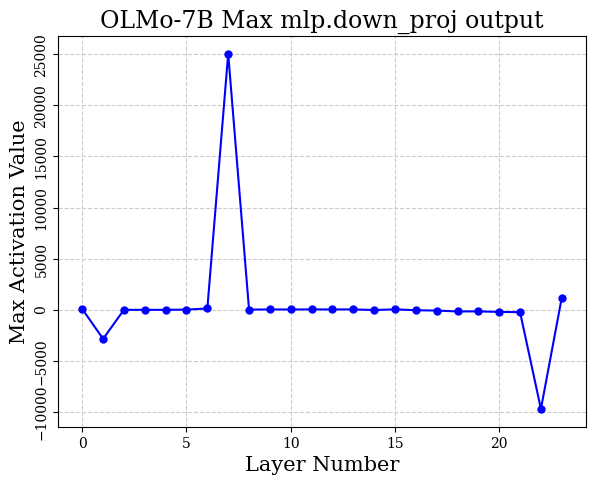

In [44]:
plot_down_proj_input_output(model=model)

## Removing 1. sw

In [50]:
SO_values = record_SO(model, pretrained, SUPER_WEIGHTS_MAP = {
            "HuggingFaceTB/SmolLM2-1.7B": [
                (7, 227, 7758),
                # (22, 227, 3997), 
                # (1, 749, 4987), 
                # (23, 749, 742)
            ]
        })
scale_SO(model, pretrained, SO_values, 0)

Layer 7, Index [227, 7758], Old value: -7.5, New value: -0.0


In [51]:
eval_ppl(model, wiki_testloader, device=DEV)

51.9468879699707

Activation spikes for mlp.down_proj input:
 - layer 1, value -373.0, index (0, 5, 4987)
 - layer 7, value -2702.0, index (0, 0, 7758)
 - layer 22, value 701.0, index (0, 0, 3997)
 - layer 23, value 127.0, index (0, 4, 1733)
largest_activations_mlp.down_proj_input=[-5.12109375, -373.0, 3.89453125, -2.474609375, 1.8701171875, 5.1953125, -15.3671875, -2702.0, 16.484375, -6.03515625, 7.58984375, 5.72265625, 8.3671875, -7.1015625, 7.2890625, 8.8203125, -14.0546875, -14.046875, -25.96875, 27.5, -49.125, 37.375, 701.0, 127.0]
Activation spikes for mlp.down_proj output:
 - layer 0, value 70.9375, index (0, 0, 227)
 - layer 1, value -2850.0, index (0, 5, 749)
 - layer 6, value 121.0625, index (0, 0, 749)
 - layer 7, value 4796.0, index (0, 0, 227)
 - layer 8, value 68.625, index (0, 5, 227)
 - layer 13, value 51.8125, index (0, 2, 227)
 - layer 14, value -53.09375, index (0, 3, 749)
 - layer 15, value 60.8125, index (0, 2, 227)
 - layer 16, value -73.1875, index (0, 1, 749)
 - layer 17, value -

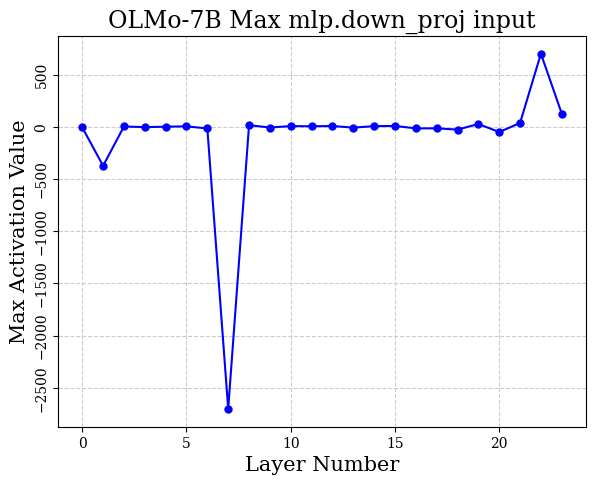

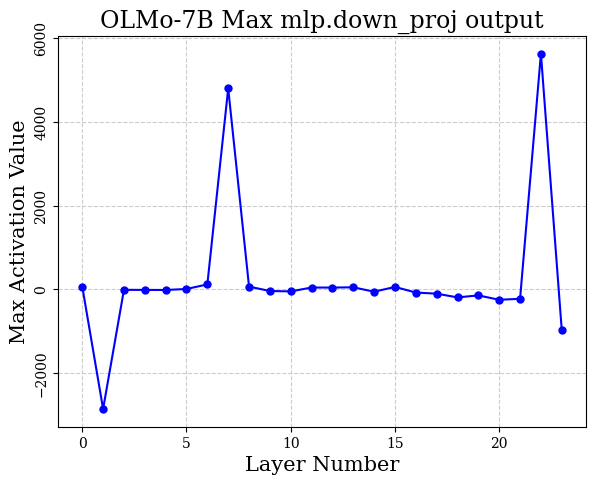

In [52]:
plot_down_proj_input_output(model=model)

## Removing 2. sw

In [7]:
SO_values = record_SO(model, pretrained, SUPER_WEIGHTS_MAP = {
            "HuggingFaceTB/SmolLM2-1.7B": [
                # (7, 227, 7758),
                (22, 227, 3997), 
                # (1, 749, 4987), 
                # (23, 749, 742)
            ]
        })
scale_SO(model, pretrained, SO_values, 0)

Layer 22, Index [227, 3997], Old value: 8.0, New value: 0.0


In [8]:
eval_ppl(model, wiki_testloader, device=DEV)

7.2756524085998535

Activation spikes for mlp.down_proj input:
 - layer 1, value -373.0, index (0, 5, 4987)
 - layer 7, value -2702.0, index (0, 0, 7758)
 - layer 21, value 51.21875, index (0, 1, 4669)
 - layer 22, value -592.0, index (0, 0, 3997)
 - layer 23, value -152.5, index (0, 8, 742)
largest_activations_mlp.down_proj_input=[-5.12109375, -373.0, 3.89453125, -2.474609375, 1.8701171875, 5.1953125, -15.3671875, -2702.0, 3.75390625, 4.76953125, 5.25, 4.64453125, -5.42578125, -4.72265625, 6.46484375, 8.140625, -17.078125, -14.578125, -15.640625, -22.125, -44.53125, 51.21875, -592.0, -152.5]
Activation spikes for mlp.down_proj output:
 - layer 0, value 70.9375, index (0, 0, 227)
 - layer 1, value -2850.0, index (0, 5, 749)
 - layer 6, value 121.0625, index (0, 0, 749)
 - layer 7, value 25056.0, index (0, 0, 227)
 - layer 17, value -83.0, index (0, 1, 749)
 - layer 18, value -169.25, index (0, 1, 749)
 - layer 19, value -161.5, index (0, 1, 749)
 - layer 20, value -214.5, index (0, 1, 749)
 - layer 21, va

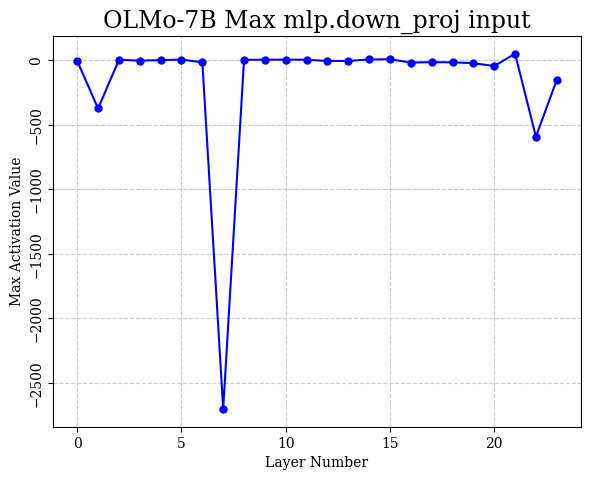

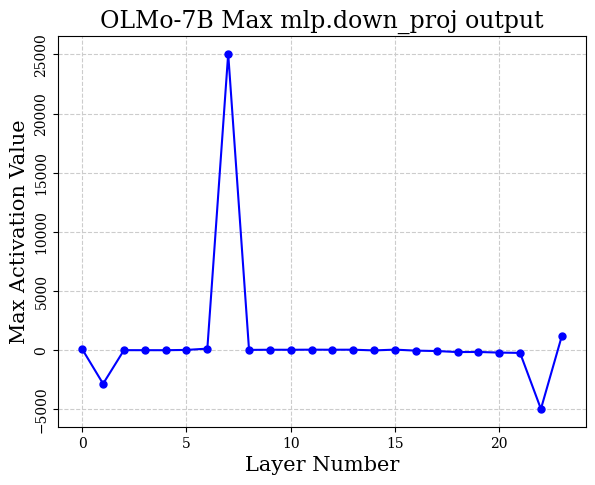

In [9]:
plot_down_proj_input_output(model=model)

## Removing 3. sw

In [11]:
SO_values = record_SO(model, pretrained, SUPER_WEIGHTS_MAP = {
            "HuggingFaceTB/SmolLM2-1.7B": [
                # (7, 227, 7758),
                # (22, 227, 3997), 
                (1, 749, 4987), 
                # (23, 749, 742)
            ]
        })
scale_SO(model, pretrained, SO_values, 0)

Layer 1, Index [749, 4987], Old value: 7.59375, New value: 0.0


In [12]:
eval_ppl(model, wiki_testloader, device=DEV)

9763617.0

Activation spikes for mlp.down_proj input:
 - layer 1, value -373.0, index (0, 5, 4987)
 - layer 6, value -54.625, index (0, 5, 2446)
 - layer 7, value -1015.0, index (0, 0, 7758)
 - layer 20, value -57.8125, index (0, 3, 7909)
 - layer 21, value 57.40625, index (0, 1, 4669)
 - layer 22, value 708.5, index (0, 5, 3997)
 - layer 23, value 146.625, index (0, 4, 1755)
largest_activations_mlp.down_proj_input=[-5.12109375, -373.0, 33.28125, 15.0859375, -8.4609375, 10.546875, -54.625, -1015.0, 5.421875, 4.390625, 2.36328125, -2.751953125, 2.4375, -4.0703125, -3.833984375, 5.6328125, 8.640625, 11.7109375, -16.390625, -27.03125, -57.8125, 57.40625, 708.5, 146.625]
Activation spikes for mlp.down_proj output:
 - layer 0, value 70.9375, index (0, 0, 227)
 - layer 1, value -588.0, index (0, 5, 161)
 - layer 2, value 102.1875, index (0, 0, 227)
 - layer 3, value -120.25, index (0, 0, 749)
 - layer 4, value -165.625, index (0, 0, 749)
 - layer 6, value 980.5, index (0, 5, 749)
 - layer 7, value 9592

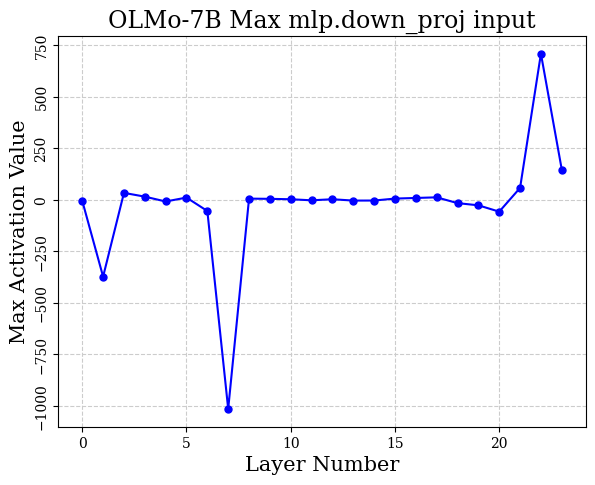

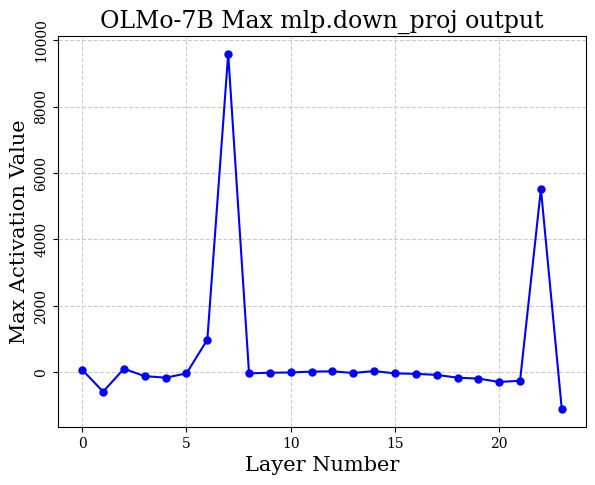

In [13]:
plot_down_proj_input_output(model=model)

## Removing 4. sw

In [15]:
SO_values = record_SO(model, pretrained, SUPER_WEIGHTS_MAP = {
            "HuggingFaceTB/SmolLM2-1.7B": [
                # (7, 227, 7758),
                # (22, 227, 3997), 
                # (1, 749, 4987), 
                (23, 749, 742)
            ]
        })
scale_SO(model, pretrained, SO_values, 0)

Layer 23, Index [749, 742], Old value: -3.765625, New value: -0.0


In [16]:
eval_ppl(model, wiki_testloader, device=DEV)

7.36646842956543

Activation spikes for mlp.down_proj input:
 - layer 1, value -373.0, index (0, 5, 4987)
 - layer 7, value -2702.0, index (0, 0, 7758)
 - layer 21, value 51.21875, index (0, 1, 4669)
 - layer 22, value -592.0, index (0, 0, 3997)
 - layer 23, value -153.0, index (0, 8, 742)
largest_activations_mlp.down_proj_input=[-5.12109375, -373.0, 3.89453125, -2.474609375, 1.8701171875, 5.1953125, -15.3671875, -2702.0, 3.75390625, 4.76953125, 5.25, 4.64453125, -5.42578125, -4.72265625, 6.46484375, 8.140625, -17.078125, -14.578125, -15.640625, -22.125, -44.53125, 51.21875, -592.0, -153.0]
Activation spikes for mlp.down_proj output:
 - layer 0, value 70.9375, index (0, 0, 227)
 - layer 1, value -2850.0, index (0, 5, 749)
 - layer 6, value 121.0625, index (0, 0, 749)
 - layer 7, value 25056.0, index (0, 0, 227)
 - layer 17, value -83.0, index (0, 1, 749)
 - layer 18, value -169.25, index (0, 1, 749)
 - layer 19, value -161.5, index (0, 1, 749)
 - layer 20, value -214.5, index (0, 1, 749)
 - layer 21, va

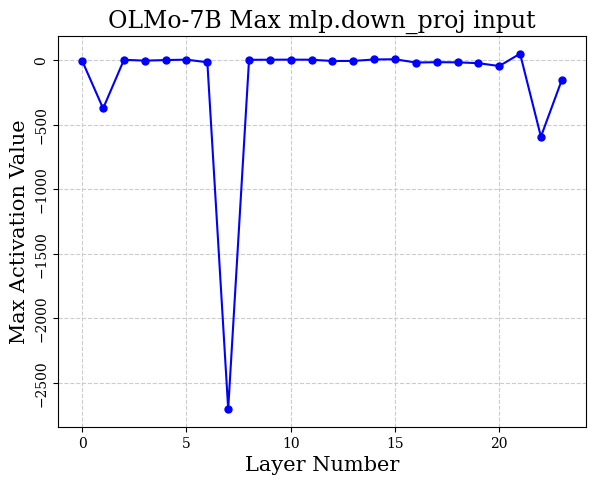

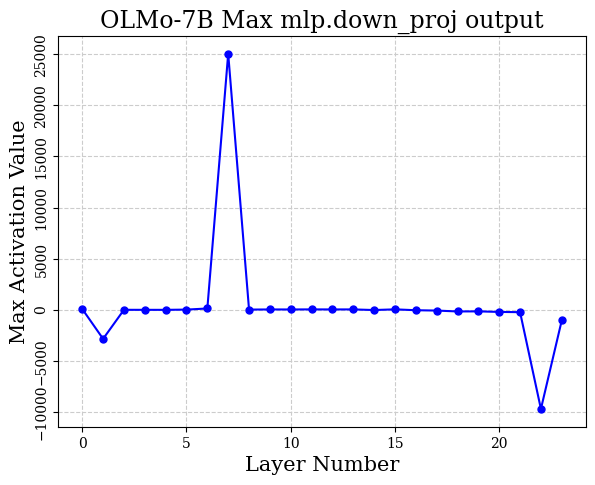

In [17]:
plot_down_proj_input_output(model=model)

# Sth else

In [25]:
import torch.nn as nn
class SkipMLP(nn.Module):
    def forward(self, x):
        return torch.zeros_like(x, device=DEV)

model.model.layers[7].mlp = SkipMLP()

Activation spikes for mlp.down_proj input:
 - layer 1, value -373.0, index (0, 5, 4987)
 - layer 7, value -2702.0, index (0, 0, 7758)
 - layer 21, value 50.90625, index (0, 1, 4669)
 - layer 22, value -348.25, index (0, 0, 3997)
 - layer 23, value -145.5, index (0, 8, 742)
largest_activations_mlp.down_proj_input=[-5.12109375, -373.0, 3.89453125, -2.474609375, 1.8701171875, 5.1953125, -15.3671875, -2702.0, 4.125, 4.96875, 5.43359375, 5.15625, -5.38671875, -5.3984375, 6.59765625, 8.1953125, -17.296875, -14.4375, -18.21875, -22.25, -47.09375, 50.90625, -348.25, -145.5]
Activation spikes for mlp.down_proj output:
 - layer 0, value 70.9375, index (0, 0, 227)
 - layer 1, value -2850.0, index (0, 5, 749)
 - layer 6, value 121.0625, index (0, 0, 749)
 - layer 7, value 14928.0, index (0, 0, 227)
 - layer 16, value -56.28125, index (0, 1, 749)
 - layer 17, value -91.0625, index (0, 1, 749)
 - layer 18, value -180.0, index (0, 1, 749)
 - layer 19, value -165.625, index (0, 1, 749)
 - layer 20, va

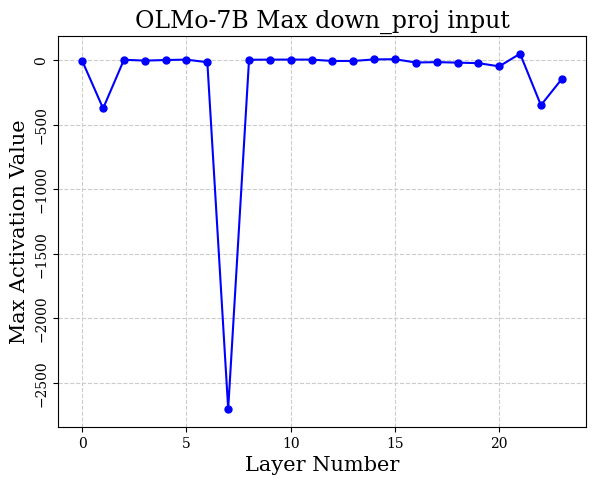

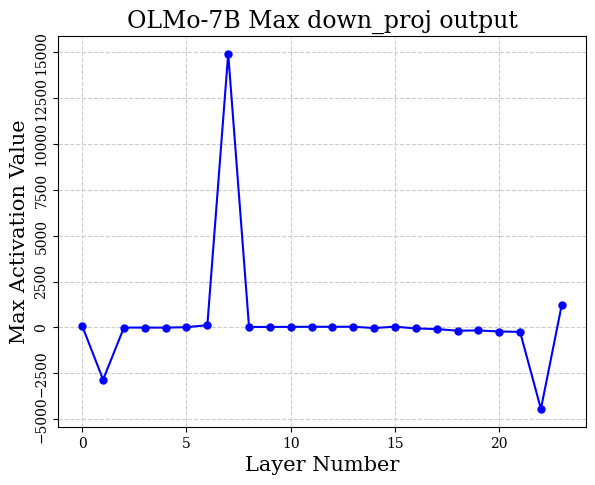

In [23]:
plot_down_proj_input_output(model=model)

---

In [76]:
eval_ppl(model, wiki_testloader, device=DEV)

7.260688781738281

In [85]:
pretrained = "HuggingFaceTB/SmolLM2-1.7B"
SO_values = record_SO(model, pretrained, SUPER_WEIGHTS_MAP = {
            "HuggingFaceTB/SmolLM2-1.7B": [
                (7, 227, 7758), 
                # (22, 227, 3997), 
                # (1, 749, 4987), 
                # (23, 749, 742)
            ]
        })
scale_SO(model, pretrained, SO_values, 0)
print('ppl:', eval_ppl(model, wiki_testloader, device=DEV))
scale_SO(model, pretrained, SO_values, 1)

Layer 7, Index [227, 7758], Old value: -7.5, New value: -0.0
ppl: 52.606407165527344
Layer 7, Index [227, 7758], Old value: -0.0, New value: -7.5


In [82]:
SO_values = record_SO(model, pretrained, SUPER_WEIGHTS_MAP = {
            "HuggingFaceTB/SmolLM2-1.7B": [
                (22, 227, 3997), 
                # (1, 749, 4987), 
                # (23, 749, 742)
            ]
        })
scale_SO(model, pretrained, SO_values, 0)
print('ppl:', eval_ppl(model, wiki_testloader, device=DEV))
scale_SO(model, pretrained, SO_values, 1)

Layer 22, Index [227, 3997], Old value: 8.0, New value: 0.0
ppl: 7.272964000701904
Layer 22, Index [227, 3997], Old value: 0.0, New value: 8.0


In [84]:
SO_values = record_SO(model, pretrained, SUPER_WEIGHTS_MAP = {
            "HuggingFaceTB/SmolLM2-1.7B": [
                (1, 749, 4987), 
                # (23, 749, 742)
            ]
        })
scale_SO(model, pretrained, SO_values, 0)
print('ppl:', eval_ppl(model, wiki_testloader, device=DEV))
scale_SO(model, pretrained, SO_values, 1)

Layer 1, Index [749, 4987], Old value: 7.59375, New value: 0.0
ppl: 30137622.0
Layer 1, Index [749, 4987], Old value: 0.0, New value: 7.59375


In [83]:
SO_values = record_SO(model, pretrained, SUPER_WEIGHTS_MAP = {
            "HuggingFaceTB/SmolLM2-1.7B": [
                (23, 749, 742)
            ]
        })
scale_SO(model, pretrained, SO_values, 0)
print('ppl:', eval_ppl(model, wiki_testloader, device=DEV))
scale_SO(model, pretrained, SO_values, 1)

Layer 23, Index [749, 742], Old value: -3.765625, New value: -0.0
ppl: 7.359472274780273
Layer 23, Index [749, 742], Old value: -0.0, New value: -3.765625


In [86]:
SO_values = record_SO(model, pretrained, SUPER_WEIGHTS_MAP = {
            "HuggingFaceTB/SmolLM2-1.7B": [
                (0, 749, 742)
            ]
        })
scale_SO(model, pretrained, SO_values, 0)
print('ppl:', eval_ppl(model, wiki_testloader, device=DEV))
scale_SO(model, pretrained, SO_values, 1)

Layer 0, Index [749, 742], Old value: 0.240234375, New value: 0.0
ppl: 7.259156227111816
Layer 0, Index [749, 742], Old value: 0.0, New value: 0.240234375
